# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import ShipsNetDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/shipsnet/",
    "csv_file": "./data/shipsnet/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = ShipsNetDataset(dataset_config)

## Show images from the dataset

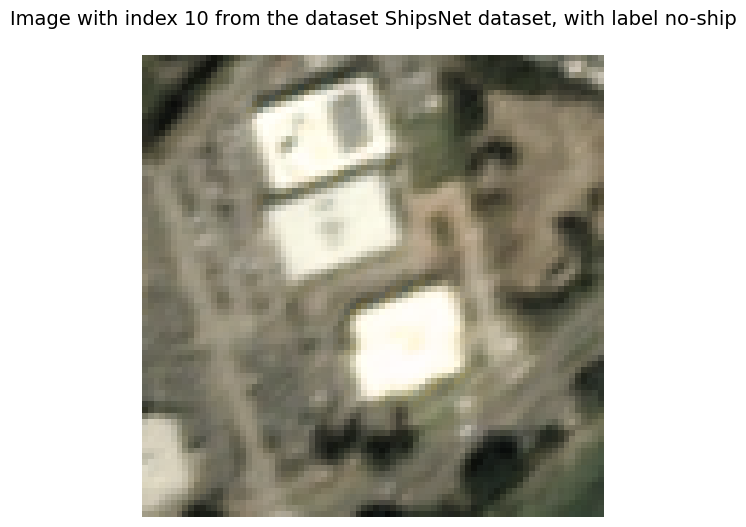

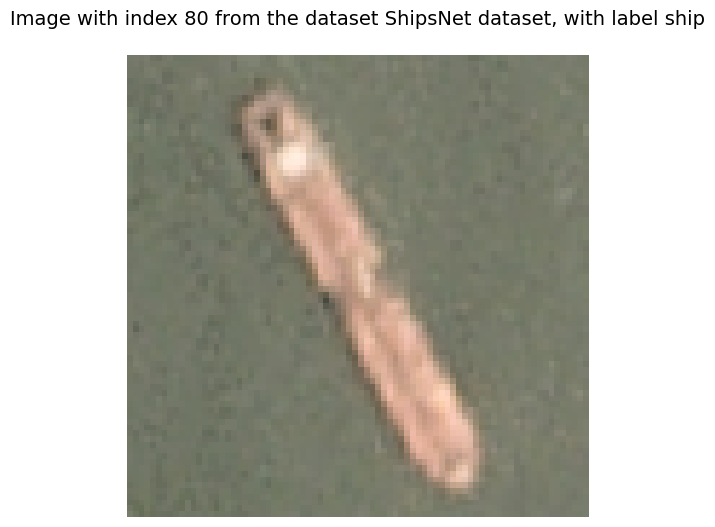

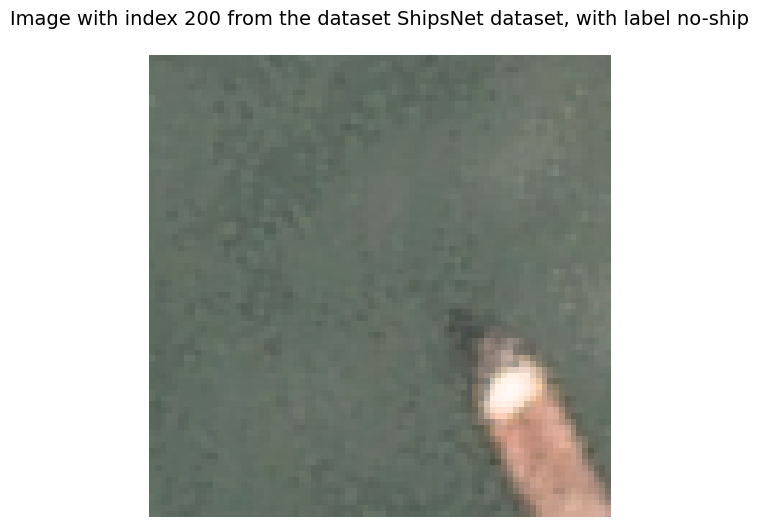

In [39]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

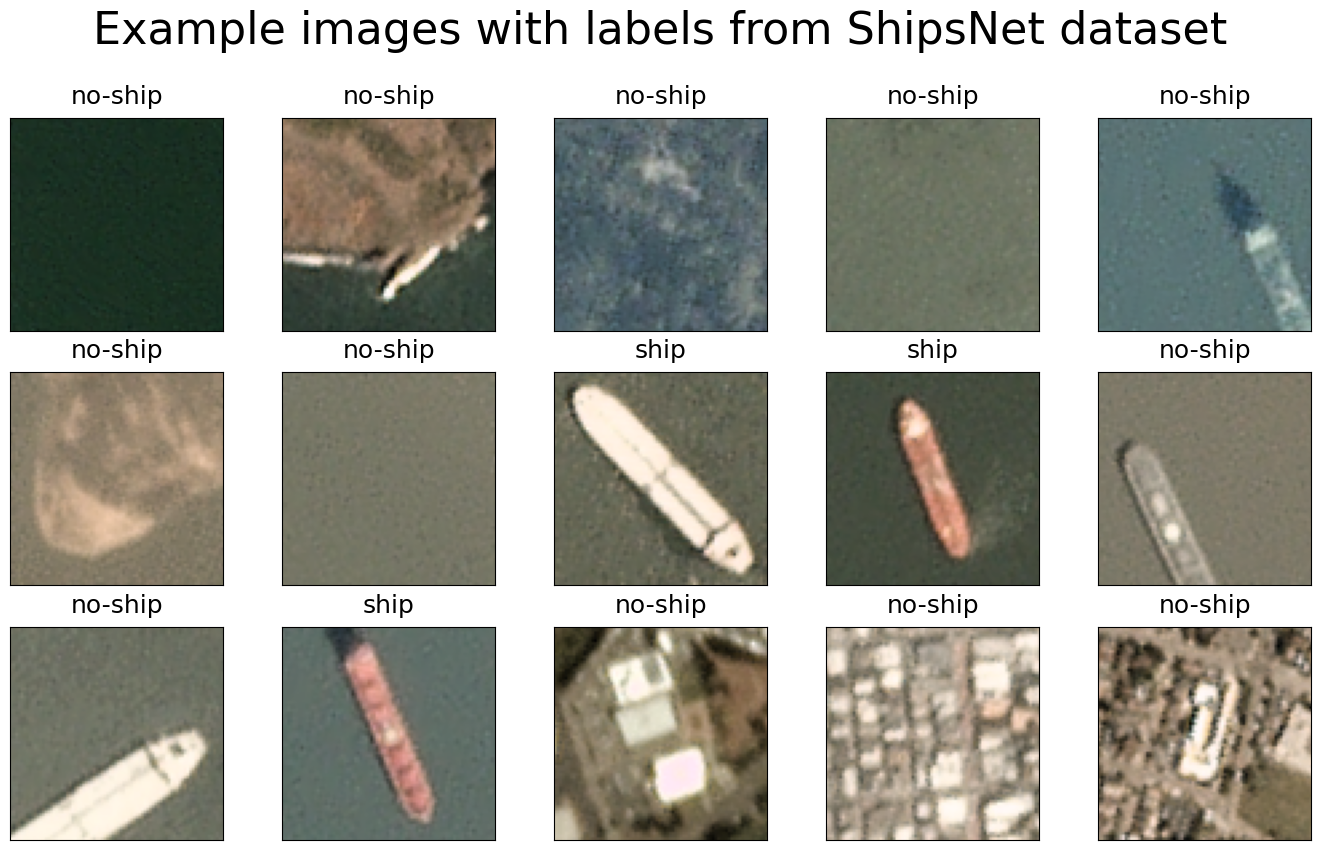

In [23]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [47]:
dataset.show_samples()

,File name,Dataset,Label
0,shipsnet/0__20161116_180803_0e14__-122.5163067...,shipsnet,no-ship
1,shipsnet/1__20161218_180845_0e26__-122.3507759...,shipsnet,ship
2,shipsnet/0__20170106_180851_0e30__-122.3417196...,shipsnet,no-ship
3,shipsnet/0__20171023_184815_0f21__-118.2166260...,shipsnet,no-ship
4,shipsnet/0__20170703_180944_1009__-122.1851355...,shipsnet,no-ship
5,shipsnet/1__20180705_213443_0f02__-122.3382913...,shipsnet,ship
6,shipsnet/1__20170622_180819_1034__-122.3305774...,shipsnet,ship
7,shipsnet/0__20170919_181413_0f1b__-122.4242339...,shipsnet,no-ship
8,shipsnet/0__20170106_180850_0e30__-122.1831601...,shipsnet,no-ship
9,shipsnet/1__20170707_181135_100b__-122.3379531...,shipsnet,ship


In [51]:
dataset.data_distribution_table()

,Label,Count
0,no-ship,2409
1,ship,784


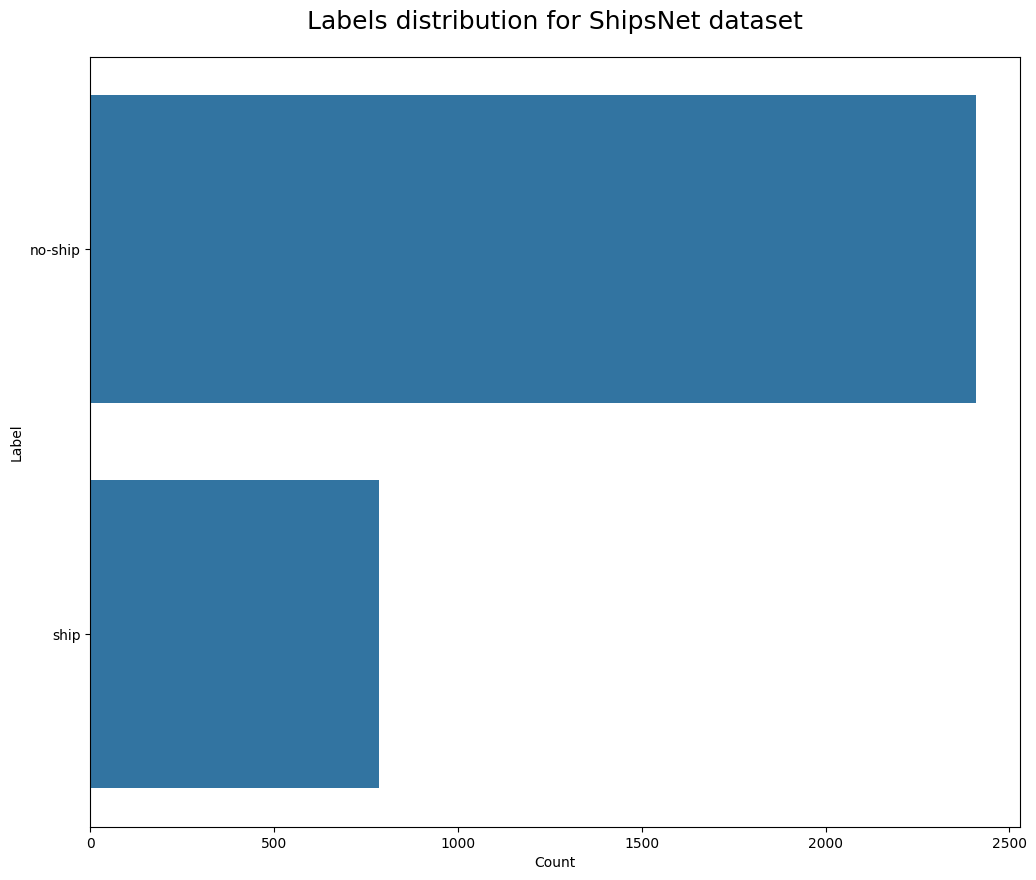

In [52]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/shipsnet/",
    "csv_file": "./data/shipsnet/train.csv",
}

train_dataset = ShipsNetDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/shipsnet/",
    "csv_file": "./data/shipsnet/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = ShipsNetDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(3193, 399)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/shipsnet/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-13 09:35:11,834 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-13 09:35:11,963 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [57]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-13 09:35:13,726 INFO Starting training.
training: 100%|██████████| 100/100 [00:51<00:00,  1.93it/s]
2025-05-13 09:36:05,781 INFO epoch: 1, time: 52, loss:  0.18182
testing on train set: 100%|██████████| 100/100 [00:20<00:00,  4.80it/s]
2025-05-13 09:36:28,966 INFO Accuracy:0.990604447228312, Precision Micro:0.990604447228312, Precision Macro:0.9826631483903108, Precision Weighted:0.9908461608264248, Precision per Class:[0.99874214 0.96658416], Recall Micro:0.990604447228312, Recall Macro:0.9924827496378377, Recall Weighted:0.990604447228312, Recall per Class:[0.98879203 0.99617347], F1_score Micro:0.9906044472283114, F1_score Macro:0.987448978308312, F1_score Weighted:0.9906517496980678, F1_score per Class:[0.99374218 0.98115578]
testing on validation set: 100%|██████████| 13/13 [00:02<00:00,  4.53it/s]
2025-05-13 09:36:31,845 INFO Accuracy:0.9874686716791979, Precision Micro:0.9874686716791979, Precision Macro:0.9774774774774775, Precision Weighted:0.9880331459278828, Precisio

0.0013107451835413957

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/shipsnet/",
    "csv_file": "./data/shipsnet/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = ShipsNetDataset(test_dataset_config)
model_path = "./data/experiments/shipsnet/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-13 10:41:44,391 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/shipsnet/checkpoint.pth.tar
2025-05-13 10:41:44,722 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/shipsnet/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 25/25 [00:01<00:00, 15.06it/s]


[{'Accuracy': 0.9974937343358395},
 {'Precision Micro': 0.9974937343358395,
  'Precision Macro': 0.9950980392156863,
  'Precision Weighted': 0.9975183055678412,
  'Precision per Class': array([1.        , 0.99019608])},
 {'Recall Micro': 0.9974937343358395,
  'Recall Macro': 0.9983221476510067,
  'Recall Weighted': 0.9974937343358394,
  'Recall per Class': array([0.9966443, 1.       ])},
 {'F1_score Micro': 0.997493734335839,
  'F1_score Macro': 0.9966966096783536,
  'F1_score Weighted': 0.9974978012983772,
  'F1_score per Class': array([0.99831933, 0.99507389])}]

## Predictions

2025-05-13 10:44:13,874 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/shipsnet/checkpoint.pth.tar
2025-05-13 10:44:14,187 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/shipsnet/checkpoint.pth.tar at epoch 21


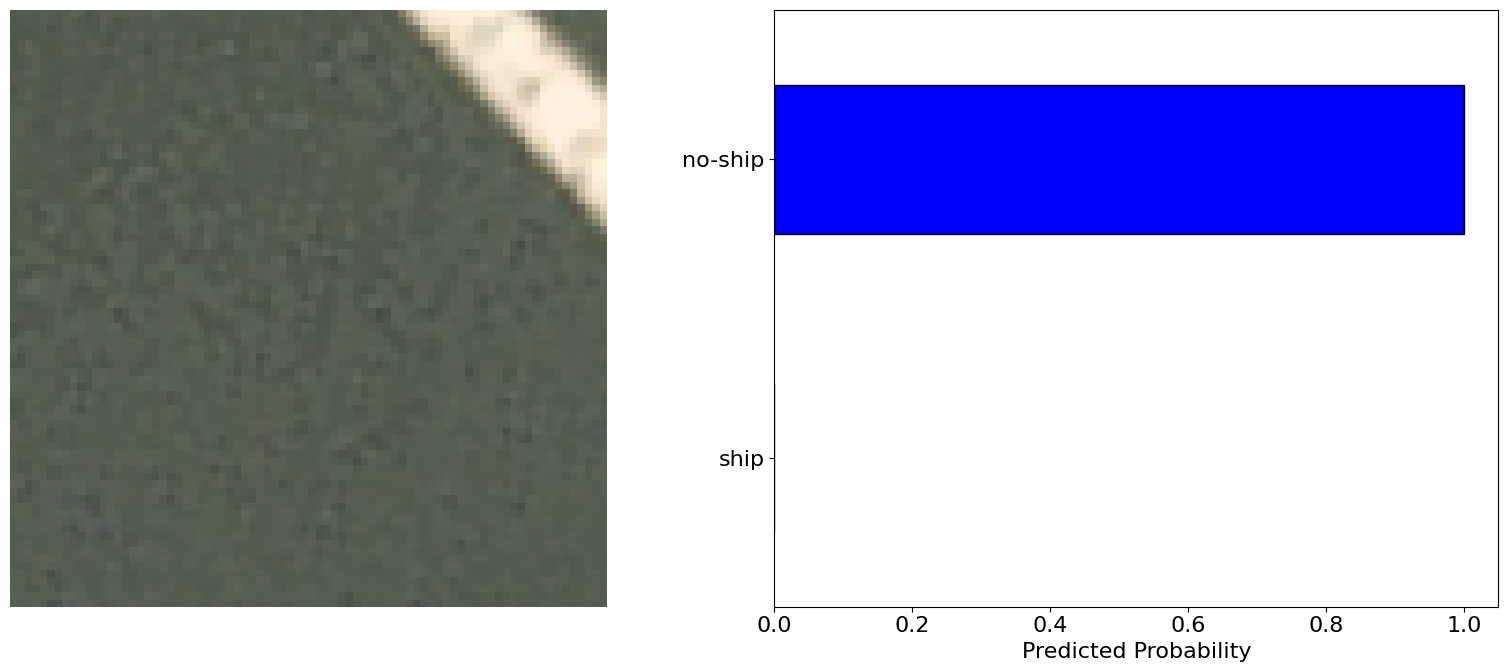

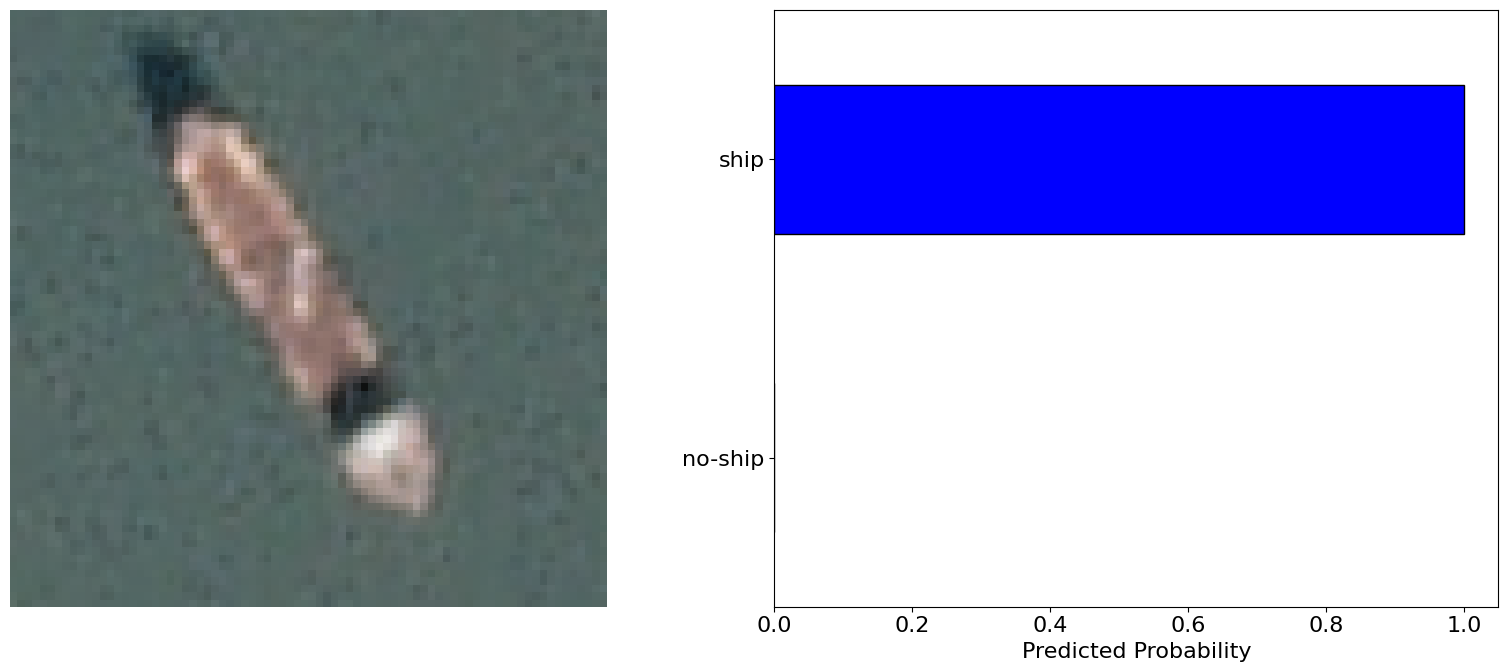

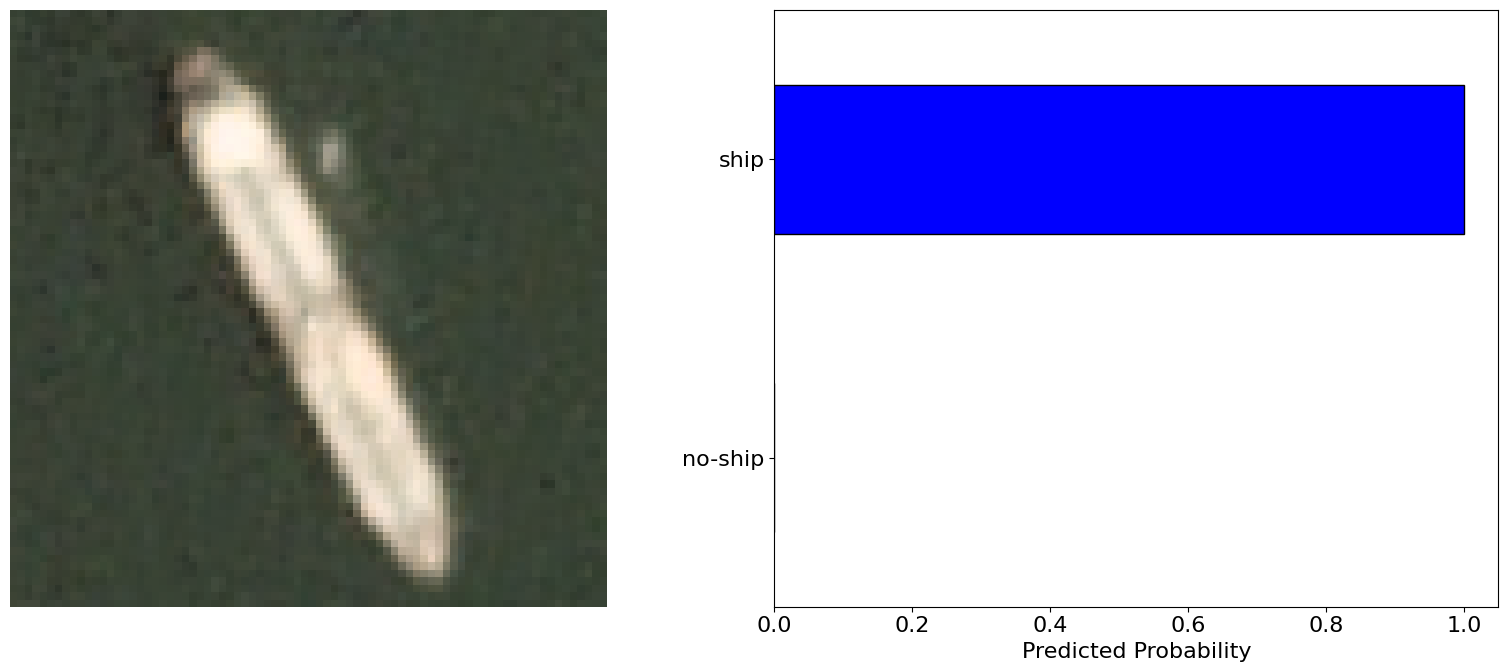

In [ ]:
labels = ["no-ship","ship"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/shipsnet/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/shipsnet/shipsnet/0__20180708_180453_0f28__-118.22646125825264_33.73718868918358.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/shipsnet/shipsnet/1__20161116_180803_0e14__-122.33870218094695_37.73731471072428.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/shipsnet/shipsnet/1__20170615_180728_1003__-122.33604657500621_37.729674652435.png')
fig = model.predict_image(image, labels, transform)